# Carga de dataset y librerias

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd 
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "viral_songs.csv"

df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, "vedauv/what-makes-a-song-go-viral-10000-tracks", file_path)

print(df.shape)
df.head()

(10000, 17)


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [14]:
df.dtypes

track_id             object
track_name           object
artist               object
genre                object
release_year          int64
duration_sec          int64
danceability        float64
energy              float64
valence             float64
tempo_bpm           float64
acousticness        float64
instrumentalness    float64
speechiness         float64
liveness            float64
loudness_db         float64
streams               int64
viral                 int64
dtype: object

## Agrupación de variables

In [15]:
numericas= ["release_year", "duration_sec", "danceability", "energy", "valence", "tempo_bpm", "acousticness", "instrumentalness", "speechiness", "liveness", "loudness_db", "streams"]
target= ["viral"]
categoricas = ["artist", "genre"]

canciones = df[numericas + categoricas + target]
canciones.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
release_year,10000.0,2017.5,4.6,2010.0,2013.0,2018.0,2022.0,2025.0
duration_sec,10000.0,208.8,50.0,60.0,175.0,209.0,242.0,433.0
danceability,10000.0,0.6,0.2,0.0,0.5,0.6,0.8,1.0
energy,10000.0,0.7,0.2,0.0,0.5,0.7,0.8,1.0
valence,10000.0,0.6,0.2,0.0,0.5,0.6,0.7,1.0
tempo_bpm,10000.0,111.0,19.0,50.0,98.0,111.3,124.5,177.8
acousticness,10000.0,0.3,0.3,0.0,0.1,0.2,0.4,1.0
instrumentalness,10000.0,0.2,0.2,0.0,0.0,0.2,0.3,0.9
speechiness,10000.0,0.1,0.1,0.0,0.0,0.1,0.1,0.4
liveness,10000.0,0.2,0.1,0.0,0.1,0.2,0.3,0.6


## Creación de kpis 

In [43]:
Kpis = {"Canciones totales" : len(df),
    "Duración primedio_sec" : df["duration_sec"].mean(),
    "Mayor reproducción": df["streams"].max(),
    "Año mas viral": df.groupby("release_year")["viral"].sum().idxmax(),
    "Cantidad de generos": df["genre"].nunique(),
    "Artistas únicos" : df["artist"].nunique(),
    "Canciones virales (%)" : df["viral"].mean()*100}

for nombre, valor in Kpis.items():
    print(f"{nombre:<30}{valor:>10,.0f}")

Canciones totales                 10,000
Duración primedio_sec                209
Mayor reproducción            443,068,342
Año mas viral                      2,014
Cantidad de generos                   10
Artistas únicos                    1,987
Canciones virales (%)                 36


## 1. Analisis de variable objetivo 


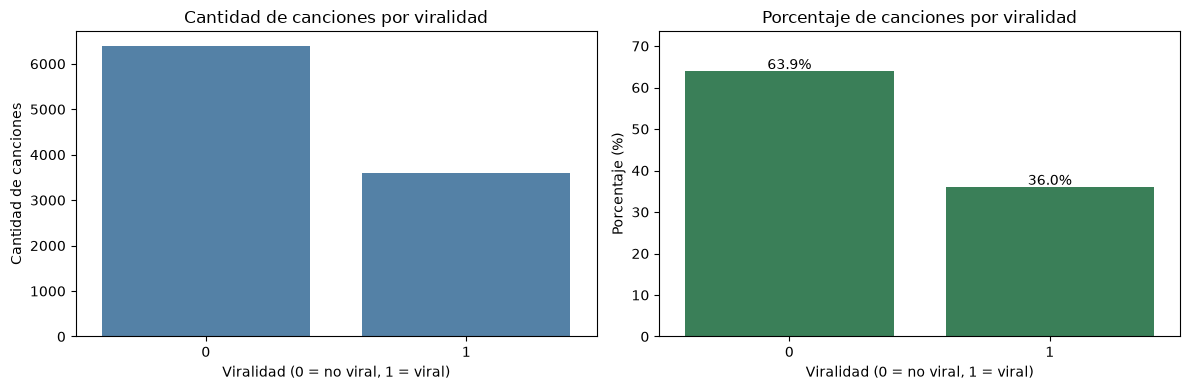

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico 1: conteo
sns.countplot(data= df, x= df["viral"], order=[0, 1], color="steelblue", ax=axes[0])
axes[0].set(
    title="Cantidad de canciones por viralidad",
    xlabel="Viralidad (0 = no viral, 1 = viral)",
    ylabel="Cantidad de canciones"
)

# Gráfico 2: porcentaje
proporciones = df["viral"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100

sns.barplot(x=proporciones.index, y=proporciones.values, color="seagreen", ax=axes[1])
axes[1].set(
    title="Porcentaje de canciones por viralidad",
    xlabel="Viralidad (0 = no viral, 1 = viral)",
    ylabel="Porcentaje (%)"
)

for i, valor in enumerate(proporciones.values):
    axes[1].text(i, valor + 0.5, f"{valor:.1f}%", ha="center")

axes[1].set_ylim(0, max(proporciones) * 1.15)

plt.tight_layout()
plt.show()

**Lectura**: La distribución presenta un desbalance moderado entre las clases, con aproximadamente 1,8 canciones no virales por cada canción viral. Aunque ambas categorías cuentan con una representación considerable. Predomina la categoría No viral.

## 2. Analisis univariado 


### 2.1 Numéricas

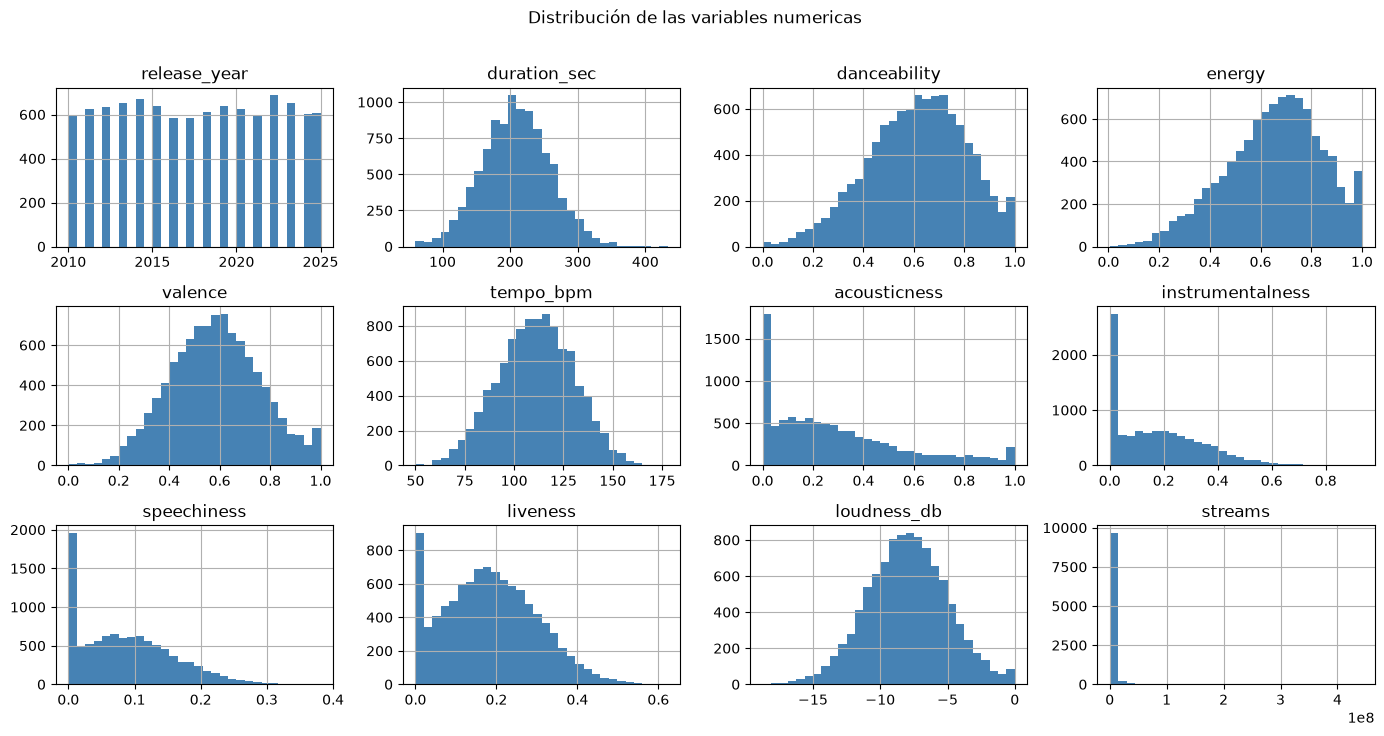

In [18]:
canciones[numericas].hist(bins = 30 , figsize= (14,9), layout= (4,4), color= "steelblue")
plt.suptitle("Distribución de las variables numericas", y = 1.01)
plt.tight_layout()
plt.show()

**Lo que encontramos en estos histogramas:**

| Patrón | Ejemplo | Implicación |
|---|---|---|
| Cola larga | streams, duration_sec | Posibles valores atípicos, especialmente en streams, conviene evaluar una transformación logarítmica. |
| Discreta / pocos valores | release_year | Variable temporal discreta, permite analizar la distribución de canciones por año. |
| Pico en 0 | acousticness, instrumentalness, speechiness, liveness | Concentración de observaciones en valores bajos y es necesario verificar si existen ceros exactos. |
| Bimodal | No se identifica claramente | No hay evidencia visual suficiente para afirmar que alguna variable presenta dos grupos diferenciados.|



### 2.2 Categóricas


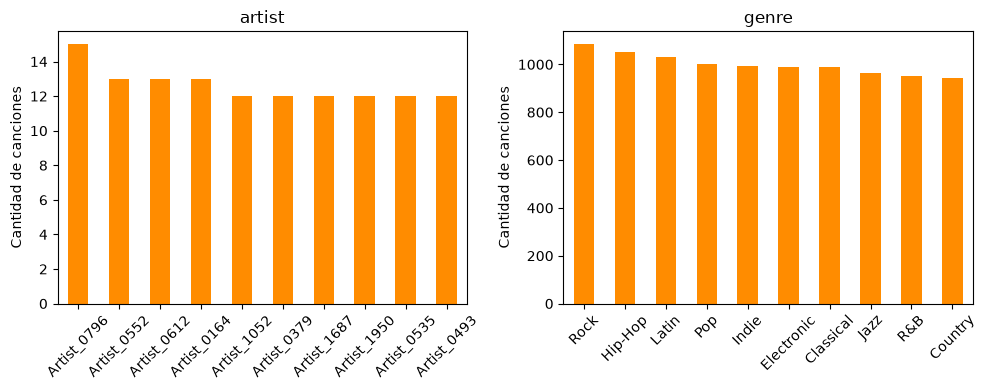

In [19]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, categoricas):
    if col in ["artist", "genre"]:
        frecuencias = df[col].value_counts().head(10)
    else:
        frecuencias = df[col].value_counts()
    frecuencias.plot(kind="bar",ax=ax,color="darkorange")
    ax.set(title=col, xlabel="", ylabel="Cantidad de canciones")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Artist**: Los 10 artistas con mayor representación presentan entre 12 y 15 canciones cada uno, destacándose Artist_0796 con 15 registros. Esto evidencia que, dentro de este grupo, no existe una concentración dominante de canciones en un solo artista.

**Genre**: Los 10 géneros presentan cantidades relativamente similares de canciones, con frecuencias aproximadas entre 940 y 1.080 registros. Esto evidencia que el dataset mantiene una distribución relativamente uniforme entre los distintos estilos musicales.

## 3. Análisis bivariado:

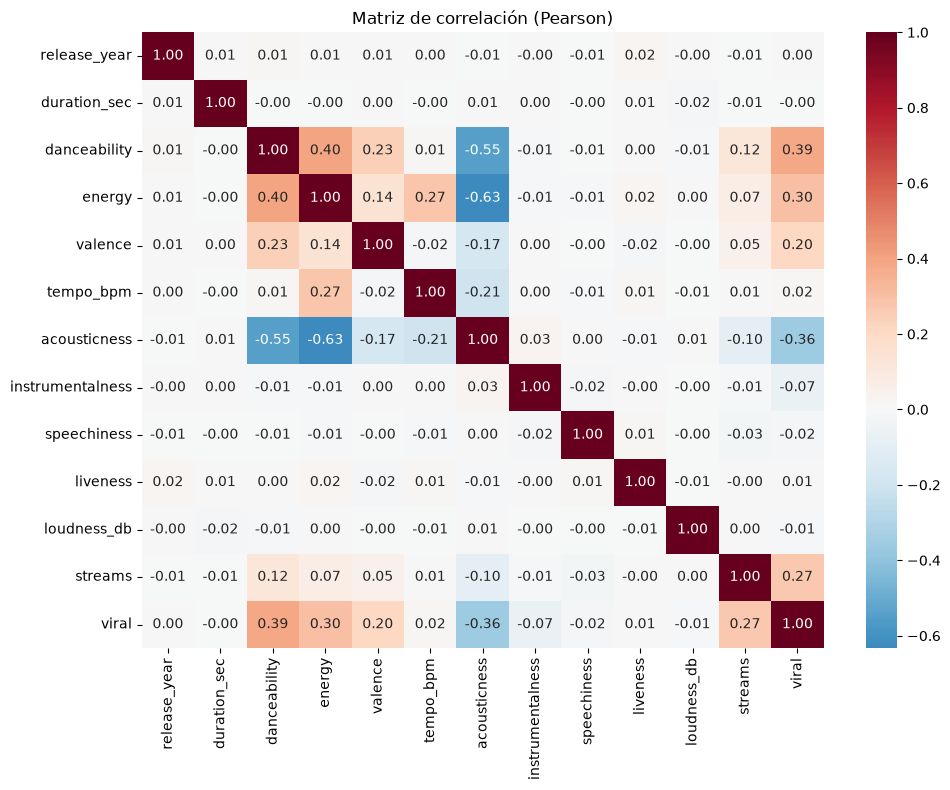

In [20]:
plt.figure(figsize=(11, 8))

sns.heatmap(df[numericas + target].corr(),annot=True,fmt=".2f",cmap="RdBu_r",center=0)
plt.title("Matriz de correlación (Pearson)")
plt.show()

In [22]:
def correlaciones_con_target(df, target):
    return (df.select_dtypes(include="number").corr()[target].drop(target).sort_values(ascending=False))
correlaciones_con_target(df, "viral").to_frame("r_con_viral").round(2)

,r_con_viral
danceability,0.39
energy,0.30
streams,0.27
valence,0.20
tempo_bpm,0.02
liveness,0.01
release_year,0.00
duration_sec,-0.00
loudness_db,-0.01
speechiness,-0.02


**Lectura**:

1. **Frente a Viral:**: Danceability (0.39), Energy (0.30), streams (0.27) son las variables más relacionadas con el viral.


### 3.2 Numéricas vs. Viral

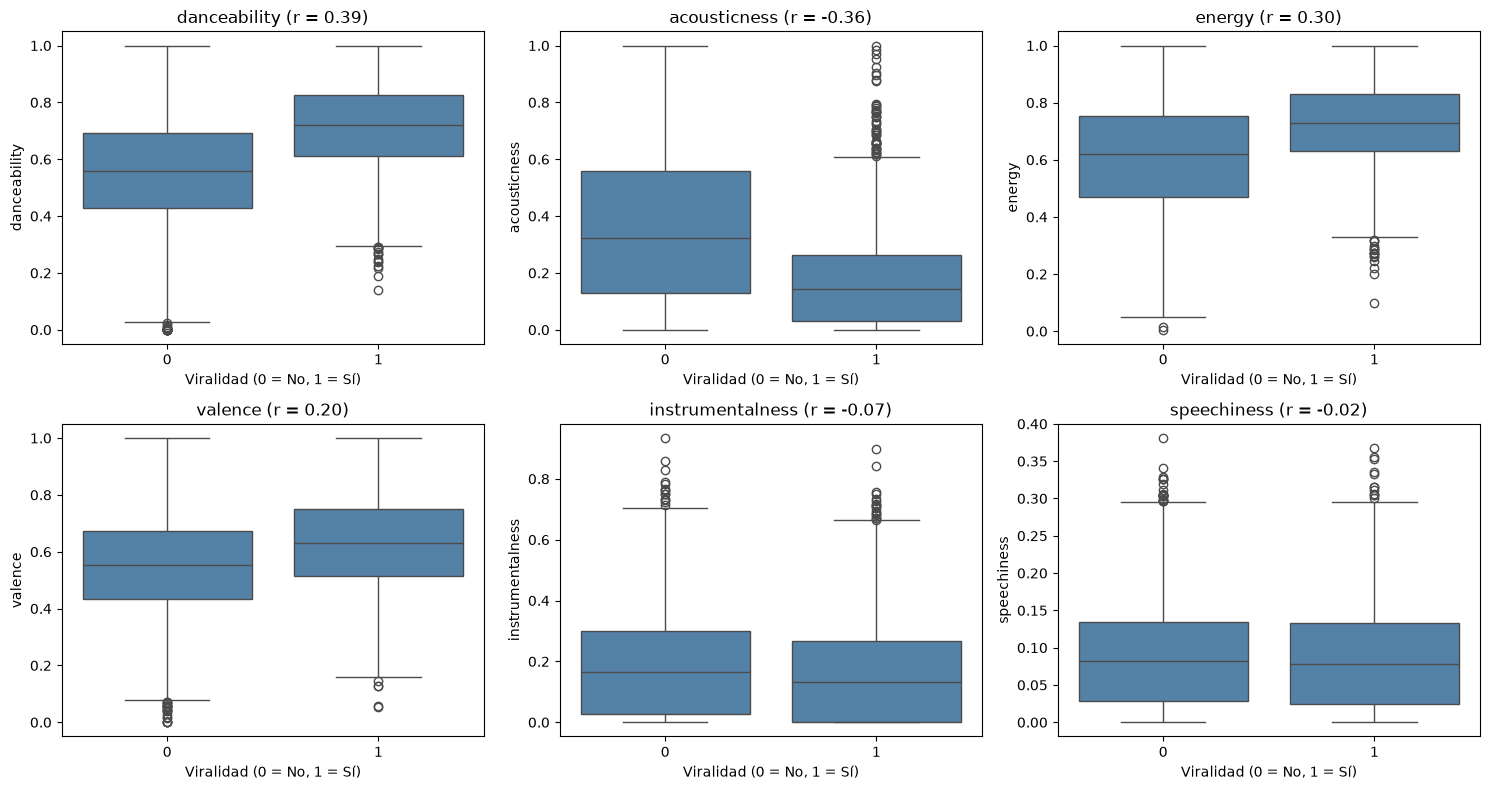

In [29]:

cols = [col for col in numericas if col != "streams"]

correlaciones = df[cols].corrwith(df["viral"])
top6 = correlaciones.abs().nlargest(6).index

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.ravel(), top6):
    sns.boxplot(data=df, x="viral", y=col, ax=ax, color="steelblue")
    ax.set(title=f"{col} (r = {correlaciones[col]:.2f})", xlabel="Viralidad (0 = No, 1 = Sí)", ylabel=col)

plt.tight_layout()
plt.show()

### 3.3 Categóricas vs. Viral

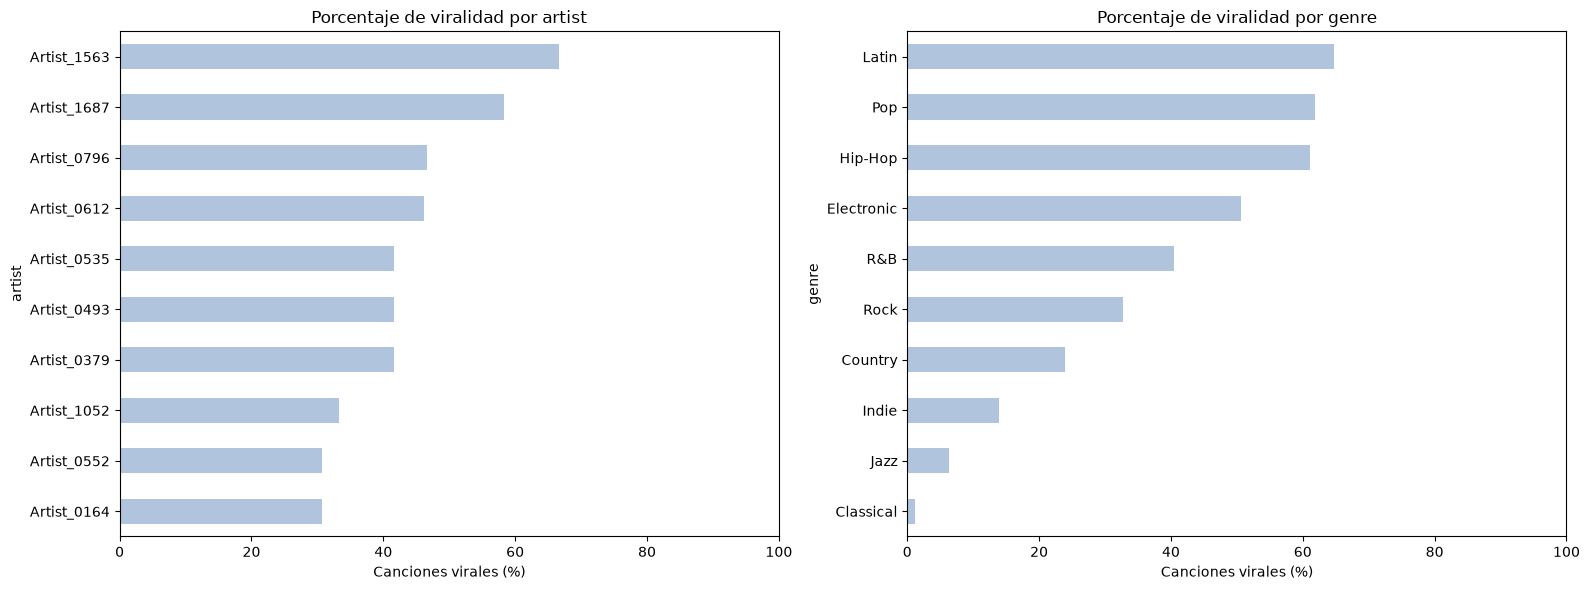

In [42]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, col in zip(axes, categoricas):
    resumen = df.groupby(col)["viral"].agg(["mean", "count"])
    if col == "artist": resumen = resumen.nlargest(10, "count")
    resumen = resumen.sort_values("mean")
    (resumen["mean"] * 100).plot(kind="barh", ax=ax, color="lightsteelblue")

    ax.set(title=f"Porcentaje de viralidad por {col}", xlabel="Canciones virales (%)", ylabel=col)
    ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()


## 4. Outliers: detectar Outliers

### 4.1 Regla del IQR

In [ ]:

# Detectamos outliers mediante IQR
def outliers_iqr(serie, k=1.5):
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - k * IQR
    limite_superior = Q3 + k * IQR
    return (serie < limite_inferior) | (serie > limite_superior)

# Resumimos los outliers
def resumen_outliers(df: pd.DataFrame, k: float = 1.5) -> pd.DataFrame:
    columnas = [col for col in numericas if col != "release_year"]
    conteo = {col: int(outliers_iqr(df[col], k).sum())
        for col in columnas}
    resumen = pd.DataFrame({"outliers": conteo})
    resumen["pct"] = (resumen["outliers"] / df[columnas].count() * 100).round(1)
    return resumen.sort_values("outliers", ascending=False)

# Mostramos las 8 variables con más valores atípicos
resumen_outliers(df).head(8)

,outliers,pct
streams,1399,14.0
acousticness,197,2.0
duration_sec,84,0.8
loudness_db,81,0.8
energy,42,0.4
danceability,39,0.4
speechiness,35,0.4
liveness,33,0.3


La variable Streams tiene el 14% de datos outlier, pero de acuerdo al contexto del Dataset, no tendrá ningún tratamiento debido a la naturaleza de los datos.

### 4.2 Los *outliers* para *duration_sec*

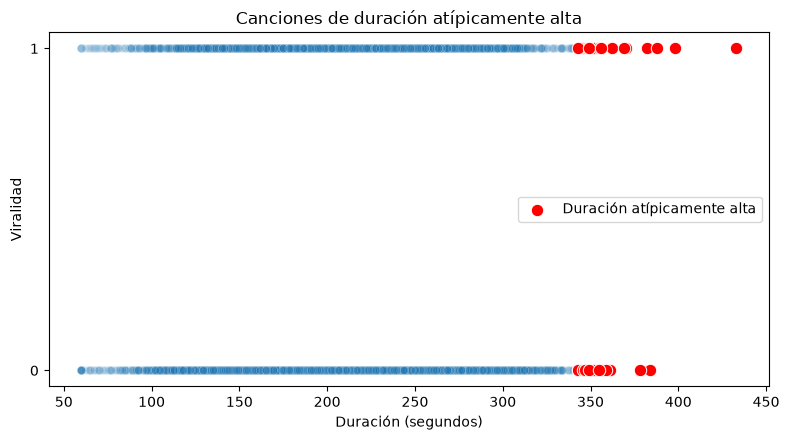

,track_name,artist,genre,duration_sec,streams,viral
1230,Track_01231,Artist_0573,Hip-Hop,433,9103998,1
7522,Track_07523,Artist_1624,Electronic,398,7978517,1
9018,Track_09019,Artist_0781,Pop,388,589486,1
5573,Track_05574,Artist_1962,Electronic,384,63007,0
7027,Track_07028,Artist_0255,Hip-Hop,382,3666540,1


In [40]:
# Calculamos el límite superior mediante IQR
Q1 = df["duration_sec"].quantile(0.25)
Q3 = df["duration_sec"].quantile(0.75)
IQR = Q3 - Q1

limite_superior = Q3 + 1.5 * IQR

# Identificamos canciones de duración atípicamente alta
largas = df[df["duration_sec"] > limite_superior]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=df, x="duration_sec", y="viral", alpha=0.15, ax=ax)
sns.scatterplot(data=largas, x="duration_sec", y="viral", color="red", s=80, ax=ax, label="Duración atípicamente alta")
ax.set(title="Canciones de duración atípicamente alta", xlabel="Duración (segundos)", ylabel="Viralidad")

ax.set_yticks([0, 1])
plt.tight_layout()
plt.show()

# Examinamos las canciones identificadas
df.loc[largas.index, ["track_name", "artist", "genre", "duration_sec", "streams", "viral"]].sort_values("duration_sec", ascending=False).head()


**Decisión:** No se elimina ni se modifica ningún de los outliers. Debido a que no hay ninguna afectación al tratamientod e los datos y como podemos ver dentro de las primeras 5 canciones con mayor duración de segundos, se encuentra presente una canción no Viral.

# Conclusiones del EDA

| # | Hallazgo | Implicación para el modelo |
|---|---|---|
| 1 | La variable objetivo viral presenta un desbalance moderado: 63,9% de canciones no virales y aproximadamente 36,0% virales. | |
| 2 |streams presenta una marcada asimetría positiva, con una concentración de valores bajos y una cola extensa hacia reproducciones elevadas. |  |
| 3 | danceability, energy y valence presentan una mayor concentración en valores medios y altos. |  |
| 4 | genre presenta una distribución relativamente equilibrada entre los 10 géneros musicales. |  |
| 5 | artist presenta numerosos artistas con pocas canciones por categoría, incluso entre los más frecuentes. |  |
| 6 | acousticness, instrumentalness, speechiness y liveness presentan concentraciones importantes cerca de cero y distribuciones asimétricas. | |
| 7 | Las distribuciones numéricas muestran posibles valores extremos, especialmente en streams, sin que estos impliquen necesariamente errores.|  |